In [1]:
#Shishir Khanal
#Aug 24, 2026
#Lunar lander using Actor_Critic algorithm
#Actions: Do nothing, Fire Left Engine, Fire main Engine, Fire Right Engine
#Positive Score - Soft landing

In [22]:
import numpy as np
import torch as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import gym
import matplotlib.pyplot as plt

In [11]:
class ActorCriticNetwork(nn.Module):
    def __init__(self, lr, input_dims, n_actions, fc1_dims=256, fc2_dims=256):
        super(ActorCriticNetwork, self).__init__()
        self.fc1 = nn.Linear(*input_dims, fc1_dims)
        self.fc2 = nn.Linear(fc1_dims, fc2_dims)
        self.pi = nn.Linear(fc2_dims, n_actions)
        self.v = nn.Linear(fc2_dims, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=lr)
        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        pi = self.pi(x)
        v = self.v(x)
        return (pi, v)

In [18]:
class Agent():
    def __init__(self, lr, input_dims, fc1_dims, fc2_dims, n_actions, gamma=0.99):
        self.gamma = gamma
        self.lr = lr
        self.fc1_dims = fc1_dims
        self.fc2_dims = fc2_dims
        self.actor_critic = ActorCriticNetwork(lr, input_dims, n_actions, fc1_dims, fc2_dims)
        self.log_prob = None


    def choose_action(self, observation):
        state = T.tensor([observation], dtype=T.float).to(self.actor_critic.device)
        probabilities, _ = self.actor_critic.forward(state)
        probabilities = F.softmax(probabilities, dim=1)
        action_probs = T.distributions.Categorical(probabilities)
        action = action_probs.sample()
        log_prob = action_probs.log_prob(action)
        self.log_prob = log_prob

        return action.item()

    def learn(self, state, reward, state_, done):
        self.actor_critic.optimizer.zero_grad()
        state = T.tensor([state], dtype=T.float).to(self.actor_critic.device)
        state_ = T.tensor([state_], dtype=T.float).to(self.actor_critic.device)
        reward = T.tensor([reward], dtype=T.float).to(self.actor_critic.device)

        _, critic_value = self.actor_critic.forward(state)
        _, critic_value_ = self.actor_critic.forward(state_)

        delta = reward + self.gamma * critic_value_ * (1-int(done)) - critic_value

        actor_loss = -self.log_prob*delta
        critic_loss = delta**2

        (actor_loss + critic_loss).backward()
        self.actor_critic.optimizer.step()

In [19]:
def plot_learning_curve(scores, x, figure_file):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])
    plt.plot(x, running_avg)
    plt.title('Running average of previous 100 scores')
    plt.show()
    plt.savefig(figure_file)

In [24]:
if __name__ == '__main__':
    #env = gym.make('LunarLander-v2', render_mode="human")
    env = gym.make('LunarLander-v2')
    agent = Agent(gamma=0.99, lr= 5e-6, input_dims=[8], n_actions=4, fc1_dims=2048, fc2_dims=1536)
    n_games = 2000
    fname = 'ACTOR_CRITIC_' + 'lunar_lander' + str(agent.fc1_dims) + '_fc1_dims_' + str(agent.fc2_dims) + '_fc2_dims_' + str(agent.lr) + '_lr_' + str(n_games) + 'games'
    figure_file = 'plots/' + fname + '.png'
    scores = []
    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            score += reward
            agent.learn(observation, reward, observation_, done)
            observation = observation_ #current state = new state
        scores.append(score)

        avg_score = np.mean(scores[-100:])
        #env.render()
        print('episode', i, 'score %.2f' % score, 'average score %.2f' % avg_score)

    x = [i+1 for i in range(len(scores))]

/home/shishir/anaconda3/lib/python3.12/site-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


episode 0 score -215.13 average score -215.13
episode 1 score -68.97 average score -142.05
episode 2 score -186.93 average score -157.01
episode 3 score -227.05 average score -174.52
episode 4 score -222.25 average score -184.07
episode 5 score -81.59 average score -166.99
episode 6 score -214.24 average score -173.74
episode 7 score -379.64 average score -199.47
episode 8 score -43.00 average score -182.09
episode 9 score -238.18 average score -187.70
episode 10 score -429.84 average score -209.71
episode 11 score -211.62 average score -209.87
episode 12 score -62.79 average score -198.56
episode 13 score -264.78 average score -203.29
episode 14 score -233.25 average score -205.28
episode 15 score -86.44 average score -197.86
episode 16 score -148.27 average score -194.94
episode 17 score -375.03 average score -204.94
episode 18 score -220.69 average score -205.77
episode 19 score -322.44 average score -211.61
episode 20 score -220.58 average score -212.03
episode 21 score -478.55 ave

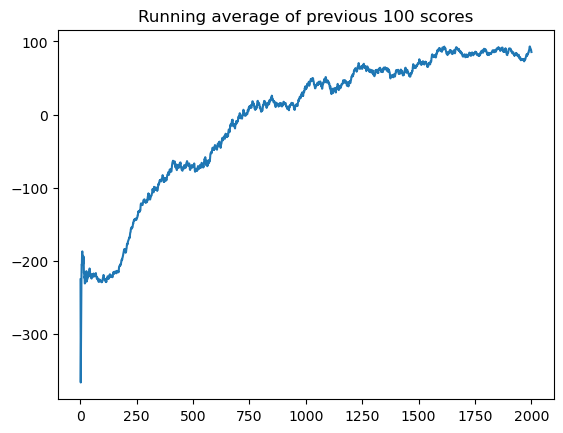

<Figure size 640x480 with 0 Axes>

In [23]:
plot_learning_curve(scores, x, figure_file)